# Baseline 1 — Independent ResNet-50 models for Unseen Plant Disease Identification
**COS30082 ML Project · Group 8 · DPD-Small**

Two **completely separate** ImageNet-pretrained ResNet-50 networks: a **crop model** that predicts the crop (55 classes) and a **disease model** that predicts the disease (175 classes). They share no parameters, have their own loss and their own optimiser, and never see each other's labels. This is the left-hand design in Fig. 1 of the brief.

Unseen classes are new *crop + disease pairings*, so we never classify pairs directly. We score every one of the 333 valid pairs by combining the two models:

$$\text{score}(c, d) = \log P_{\text{crop model}}(c) + \log P_{\text{disease model}}(d) + b\cdot\mathbb{1}[(c,d)\ \text{not trained on}]$$

The calibration bias $b$ offsets the models' natural preference for seen pairs.

### Why this is set up exactly like Baseline 2
The data pipeline, augmentation, pseudo-unseen validation split, hyperparameters and evaluation functions are copied **unchanged** from the team's Baseline 2 notebook (multi-task ResNet-50). The only difference is *two networks instead of one shared backbone*, so any gap between the two baselines is caused by sharing the representation, nothing else.

### How to run (two passes)
1. **`run_mode='dev'`**: holds out the same 15 seen pairs as Baseline 2 as *pseudo-unseen* validation. It picks the best epoch and the bias $b$ **without touching the test set**.
2. **`run_mode='final'`**: retrains both models on all 8 000 training images for the chosen number of epochs, then reports Top-1/Top-5, harmonic mean and confusion matrices on the real test sets using the dev bias.

**Data:** either an extracted `DPD_Small` folder uploaded to Google Drive (found automatically, see section 3) or the team archive `MyDrive/COS30082/DPD_Small.7z`. If Baseline 2 has already been run from the same Drive folder, the resized cache `MyDrive/COS30082/cache/dpd_small_320.zip` is reused and setup takes about a minute.

**Opening it:** upload this notebook to Google Drive, then right-click it → *Open with* → *Google Colaboratory*. No GitHub access is needed.

**Runtime:** two ResNet-50s, so each epoch takes roughly twice as long as Baseline 2 (about 2 min on a T4). Checkpoints save to Drive every epoch, so after a Colab disconnect just *Run all* again and it resumes.

## 1. Environment setup

In [30]:
import os, sys, json, time, math, random, shutil, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'   # mixed precision only on GPU
print('device:', DEVICE, torch.cuda.get_device_name(0) if AMP else '(no GPU: Runtime > Change runtime type > T4)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda Tesla T4


## 2. Configuration
Everything you might change lives here. Run the notebook once with `run_mode='dev'`, then once with `run_mode='final'`. The values match Baseline 2, so both baselines are trained the same way. Both models use the same settings.

In [31]:
CFG = dict(
    run_mode='dev',          # 'dev' = tune on pseudo-unseen split | 'final' = train on all 8000, evaluate on test
    drive_root='/content/drive/MyDrive/COS30082',   # team Drive folder holding DPD_Small.7z
    archive_name='DPD_Small.7z',
    dataset_dir=None,        # optional: Drive path of an extracted DPD_Small folder (found automatically if left as None)
    data_root='/content/data',   # where the archive is extracted
    local_root='/content',   # fast local disk for the resized image cache
    cache_size=320,          # shorter image side after a one-off resize (originals are up to 4000px)
    backbone='resnet50.a1_in1k',   # used for BOTH models (same backbone as Baseline 2)
    pretrained=True,
    img_size=224,
    batch_size=64,
    epochs=25,               # dev: max epochs (best one is kept) | final: replaced by the dev best epoch
    freeze_epochs=1,         # train only each model's head first, then unfreeze its backbone
    warmup_epochs=1,
    lr_backbone=1e-4,
    lr_heads=1e-3,
    weight_decay=0.05,
    label_smoothing=0.1,
    dropout=0.2,
    num_holdout_pairs=15,    # dev only: seen pairs held out as pseudo-unseen validation
    val_frac=0.1,            # dev only: share of each remaining pair kept for seen validation
    num_workers=2,
    seed=42,                 # same seed as Baseline 2, so the pseudo-unseen pairs are identical
)
# Local CPU smoke tests override settings through an env var (unused on Colab)
if os.environ.get('DPD_CFG'):
    CFG.update(json.loads(os.environ['DPD_CFG']))
assert CFG['run_mode'] in ('dev', 'final')

CACHE_DIR = os.path.join(CFG['local_root'], f"dpd_small_{CFG['cache_size']}")
CACHE_ZIP = os.path.join(CFG['drive_root'], 'cache', f"dpd_small_{CFG['cache_size']}.zip")   # shared with Baseline 2
OUT_ROOT = os.path.join(CFG['drive_root'], 'outputs', 'baseline1_independent_resnet50')
OUT_DIR = os.path.join(OUT_ROOT, CFG['run_mode'])
DEV_SUMMARY = os.path.join(OUT_ROOT, 'dev', 'summary.json')
BASELINE2_METRICS = os.path.join(CFG['drive_root'], 'outputs', 'baseline2_multitask_resnet50', 'final', 'metrics.json')
os.makedirs(OUT_DIR, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG['seed'])
print(json.dumps(CFG, indent=2))

{
  "run_mode": "dev",
  "drive_root": "/content/drive/MyDrive/COS30082",
  "archive_name": "DPD_Small.7z",
  "dataset_dir": null,
  "data_root": "/content/data",
  "local_root": "/content",
  "cache_size": 320,
  "backbone": "resnet50.a1_in1k",
  "pretrained": true,
  "img_size": 224,
  "batch_size": 64,
  "epochs": 25,
  "freeze_epochs": 1,
  "warmup_epochs": 1,
  "lr_backbone": 0.0001,
  "lr_heads": 0.001,
  "weight_decay": 0.05,
  "label_smoothing": 0.1,
  "dropout": 0.2,
  "num_holdout_pairs": 15,
  "val_frac": 0.1,
  "num_workers": 2,
  "seed": 42
}


## 3. Get the data onto Colab's local disk
Originals are up to 4000px, and decoding them every step would make the GPU wait on the CPU. So the first time, every image is resized once so its shorter side is 320px, and that small copy (images + CSVs) is saved to Drive as `cache/dpd_small_320.zip`. Later sessions just unzip it, which takes about 1 minute.

The notebook finds the data in the first of these places that exists:
1. **The resized cache** `MyDrive/COS30082/cache/dpd_small_320.zip` (made by an earlier run of this notebook or of Baseline 2).
2. **An extracted `DPD_Small` folder on Drive**, holding the three CSVs and the `DPD_Small_dataset/` image folder. It is found automatically up to two folders below `MyDrive` (e.g. `MyDrive/DPD_Small` or `MyDrive/COS30082-ML-Project/DPD_Small`). Anywhere else, set `dataset_dir` in the config.
3. **The team archive** `MyDrive/COS30082/DPD_Small.7z` (about 3.4 GB), copied to local disk and extracted, as in Baseline 2.

Reading an extracted folder straight from Drive is slower than the archive the first time (expect 10–20 min for the one-off resize), but after that the cache is used and it makes no difference.

In [32]:
import glob
from concurrent.futures import ThreadPoolExecutor
CSV_NAMES = ['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv']
SRC_IMAGES = os.path.join(CFG['data_root'], 'DPD_Small_dataset')   # replaced if an extracted folder is found on Drive
IMAGE_DIR = os.path.join(CACHE_DIR, 'DPD_Small_dataset')
MY_DRIVE = os.path.dirname(CFG['drive_root'])   # /content/drive/MyDrive

def is_dataset_folder(path):
    return (path is not None and os.path.isdir(os.path.join(path, 'DPD_Small_dataset'))
            and all(os.path.exists(os.path.join(path, n)) for n in CSV_NAMES))

def find_extracted_folder():
    # An already-extracted DPD_Small folder on Drive (3 CSVs + DPD_Small_dataset/), or None
    if CFG['dataset_dir']:
        if not is_dataset_folder(CFG['dataset_dir']):
            raise FileNotFoundError(f"dataset_dir={CFG['dataset_dir']!r} must contain {CSV_NAMES} and DPD_Small_dataset/")
        return CFG['dataset_dir']
    candidates = [os.path.join(CFG['drive_root'], 'DPD_Small'), CFG['drive_root']]
    if os.path.isdir(MY_DRIVE):   # look up to two folders below MyDrive
        for pattern in (('*',), ('*', '*')):
            candidates += sorted(os.path.dirname(p) for p in glob.glob(os.path.join(MY_DRIVE, *pattern, CSV_NAMES[0])))
    return next((c for c in candidates if is_dataset_folder(c)), None)

def extract_archive():
    if os.path.exists(os.path.join(CFG['data_root'], CSV_NAMES[0])):
        return
    archive = os.path.join(CFG['drive_root'], CFG['archive_name'])
    if not os.path.exists(archive):
        raise FileNotFoundError(
            f'No DPD-Small data found. Looked for {CACHE_ZIP}, an extracted DPD_Small folder up to two levels '
            f'below {MY_DRIVE}, and {archive}. Set dataset_dir in the config to the folder holding the CSVs.')
    local_archive = os.path.join(CFG['local_root'], CFG['archive_name'])
    print('copying', archive, 'to local disk ...')
    shutil.copy(archive, local_archive)
    print('extracting ...')
    subprocess.run(['7z', 'x', '-y', local_archive, f"-o{CFG['data_root']}"], check=True, stdout=subprocess.DEVNULL)
    os.remove(local_archive)

# Phone photos store their rotation in an EXIF tag. ImageOps.exif_transpose crashes on
# some DPD images whose EXIF is malformed (e.g. a resolution tag saved as text), so we
# read only the orientation tag ourselves and drop the rest of the EXIF.
ORIENTATION_FIX = {2: Image.Transpose.FLIP_LEFT_RIGHT, 3: Image.Transpose.ROTATE_180,
                   4: Image.Transpose.FLIP_TOP_BOTTOM, 5: Image.Transpose.TRANSPOSE,
                   6: Image.Transpose.ROTATE_270, 7: Image.Transpose.TRANSVERSE,
                   8: Image.Transpose.ROTATE_90}

def load_upright(path):
    with Image.open(path) as im:
        try:
            orientation = im.getexif().get(0x0112, 1)
        except Exception:
            orientation = 1
        im = im.convert('RGB')
    if orientation in ORIENTATION_FIX:
        im = im.transpose(ORIENTATION_FIX[orientation])
    im.info = {}
    return im

def resize_one(name):
    dst = os.path.join(IMAGE_DIR, name)
    if os.path.exists(dst):
        return
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    im = load_upright(os.path.join(SRC_IMAGES, name))
    scale = CFG['cache_size'] / min(im.size)
    if scale < 1:
        im = im.resize((round(im.width * scale), round(im.height * scale)), Image.BICUBIC)
    im.save(dst, quality=95)

def prepare_data():
    global SRC_IMAGES
    done_flag = os.path.join(CACHE_DIR, '.complete')
    if not os.path.exists(done_flag) and os.path.exists(CACHE_ZIP):
        print('unpacking resized dataset from Drive ...')
        shutil.unpack_archive(CACHE_ZIP, CFG['local_root'])
    if os.path.exists(done_flag):
        print('dataset ready:', CACHE_DIR)
        return
    src = find_extracted_folder()
    if src:
        print('using the extracted dataset folder on Drive:', src)
    else:
        extract_archive()
        src = CFG['data_root']
    SRC_IMAGES = os.path.join(src, 'DPD_Small_dataset')
    os.makedirs(IMAGE_DIR, exist_ok=True)
    for name in CSV_NAMES:
        shutil.copy(os.path.join(src, name), CACHE_DIR)
    names = pd.concat([pd.read_csv(os.path.join(CACHE_DIR, n), header=None)[0] for n in CSV_NAMES]).unique()
    missing = sorted(set(names) - set(os.listdir(SRC_IMAGES)))   # catches an unfinished Drive upload
    if missing:
        raise FileNotFoundError(f'{len(missing)} of {len(names)} images listed in the CSVs are missing from '
                                f'{SRC_IMAGES} (e.g. {missing[:3]}). Finish the upload and run again.')
    print(f'resizing {len(names)} images (one-off) ...')
    with ThreadPoolExecutor(16) as pool:
        for i, _ in enumerate(pool.map(resize_one, names), 1):
            if i % 1000 == 0:
                print(f'  {i}/{len(names)}')
    open(done_flag, 'w').close()
    os.makedirs(os.path.dirname(CACHE_ZIP), exist_ok=True)
    shutil.make_archive(CACHE_ZIP[:-4], 'zip', CFG['local_root'], os.path.basename(CACHE_DIR))
    print('saved resized dataset to Drive:', CACHE_ZIP)

prepare_data()
TRAIN_CSV, TEST_SEEN_CSV, TEST_UNSEEN_CSV = (os.path.join(CACHE_DIR, n) for n in CSV_NAMES)

dataset ready: /content/dpd_small_320


## 4. Load metadata and build the composition table
CSV columns (no header): `file, crop_id, disease_id, comp_id, crop_name, disease_name, comp_name`.
`COMP_CROP[k]` and `COMP_DIS[k]` give the crop and disease of composition `k`, which is all we need to turn the two heads' outputs into pair scores.

In [33]:
COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']

def read_split(path):
    return pd.read_csv(path, header=None, names=COLS)

train_df = read_split(TRAIN_CSV)
test_seen_df = read_split(TEST_SEEN_CSV)
test_unseen_df = read_split(TEST_UNSEEN_CSV)
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

# Every composition id must map to exactly one (crop, disease) pair
assert (all_df.groupby('comp')[['crop', 'disease']].nunique() == 1).all().all()
comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))
assert comps['comp'].tolist() == list(range(len(comps))), 'composition ids should run 0..N-1'

NUM_CROPS = int(all_df['crop'].max()) + 1
NUM_DISEASES = int(all_df['disease'].max()) + 1
NUM_COMPS = len(comps)
COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
COMP_NAMES = comps['comp_name'].tolist()
CROP_NAMES = all_df.drop_duplicates('crop').set_index('crop')['crop_name'].sort_index().tolist()

TRAIN_COMPS = set(train_df['comp'])
UNSEEN_COMPS = set(test_unseen_df['comp'])
assert not TRAIN_COMPS & UNSEEN_COMPS, 'unseen pairs leaked into training'
print(f'train {len(train_df)} | test-seen {len(test_seen_df)} | test-unseen {len(test_unseen_df)}')
print(f'crops {NUM_CROPS} | diseases {NUM_DISEASES} | compositions {NUM_COMPS} '
      f'(seen {len(TRAIN_COMPS)}, unseen {len(UNSEEN_COMPS)})')

train 8000 | test-seen 2000 | test-unseen 1448
crops 55 | diseases 175 | compositions 333 (seen 323, unseen 10)


## 5. Can the unseen pairs be predicted at all?
A pair can only be predicted if its crop **and** its disease each appear somewhere in training. We also count how many diseases occur on 2+ crops. Those are the diseases where crop-independent symptom features matter, and they set how much room the contrastive method has to improve.

In [34]:
dis_crops = train_df.groupby('disease')['crop'].nunique()
pair_counts = train_df.groupby('comp').size()
print(f'diseases seen on 2+ crops: {(dis_crops >= 2).sum()} / {len(dis_crops)}')
print(f'train images per pair: min {pair_counts.min()} | median {int(pair_counts.median())} | max {pair_counts.max()}')

rows = []
for c in sorted(UNSEEN_COMPS):
    r = comps.loc[c]
    rows.append(dict(
        pair=r.comp_name,
        train_imgs_of_crop=int((train_df['crop'] == r.crop).sum()),
        train_imgs_of_disease=int((train_df['disease'] == r.disease).sum()),
        crops_with_this_disease=int(dis_crops.get(r.disease, 0)),
        test_imgs=int((test_unseen_df['comp'] == c).sum()),
    ))
unseen_table = pd.DataFrame(rows)
display(unseen_table)
blocked = unseen_table[(unseen_table.train_imgs_of_crop == 0) | (unseen_table.train_imgs_of_disease == 0)]
print('WARNING, unpredictable pairs:' if len(blocked) else
      'OK: every unseen pair has its crop and its disease in training', *blocked.pair)

diseases seen on 2+ crops: 42 / 175
train images per pair: min 1 | median 7 | max 544


,pair,train_imgs_of_crop,train_imgs_of_disease,crops_with_this_disease,test_imgs
0,pepper_bell_bacterial_spot,63,188,5,220
1,cherry_aphis_spp,83,7,2,72
2,corn_brown_spot,910,261,8,35
3,cotton_bacterial_blight,56,147,3,125
4,cucumber_downy_mildew,36,69,11,32
5,cucumber_powdery_mildew,36,226,11,37
6,grape_black_rot,167,36,5,271
7,mango_anthracnose,134,51,9,95
8,sugarcane_rust,162,297,12,89
9,tomato_early_blight,1164,102,2,472


OK: every unseen pair has its crop and its disease in training


## 6. Splits — pseudo-unseen validation
The real unseen test can't be used for tuning. In **dev** mode we hold out 15 seen pairs whose crop and disease both still appear in other training pairs, so they mimic the real unseen pairs. This *val-unseen* set picks the epoch and bias. Another 10% of every remaining pair becomes *val-seen*.

In **final** mode we train on all 8 000 images.

`NOVEL_MASK` marks every pair the model did **not** train on. Those pairs receive the bias $b$.

In [35]:
def make_dev_split(df, k, val_frac, seed):
    rng = np.random.RandomState(seed)
    pairs = df.groupby('comp').agg(crop=('crop', 'first'), disease=('disease', 'first'))
    remaining, holdout = pairs.copy(), []
    for c in rng.permutation(pairs.index.values):
        if len(holdout) == k:
            break
        rest = remaining.drop(c)
        # the held-out pair's crop and disease must stay seen elsewhere, as for real unseen pairs
        if (rest['crop'] == pairs.at[c, 'crop']).any() and (rest['disease'] == pairs.at[c, 'disease']).any():
            holdout.append(int(c))
            remaining = rest
    val_unseen = df[df['comp'].isin(holdout)]
    rest_df = df[~df['comp'].isin(holdout)]
    val_idx = []
    for _, g in rest_df.groupby('comp'):
        n_val = int(len(g) * val_frac)   # pairs with < 10 images keep everything for training
        if n_val:
            val_idx += g.sample(n_val, random_state=seed).index.tolist()
    val_seen = rest_df.loc[val_idx]
    fit = rest_df.drop(index=val_idx)
    return (fit.reset_index(drop=True), val_seen.reset_index(drop=True),
            val_unseen.reset_index(drop=True), sorted(holdout))

if CFG['run_mode'] == 'dev':
    fit_df, val_seen_df, val_unseen_df, HOLDOUT = make_dev_split(
        train_df, CFG['num_holdout_pairs'], CFG['val_frac'], CFG['seed'])
    print(f'fit {len(fit_df)} | val-seen {len(val_seen_df)} | val-unseen {len(val_unseen_df)} '
          f'({len(HOLDOUT)} pseudo-unseen pairs)')
    print('pseudo-unseen pairs:', ', '.join(COMP_NAMES[c] for c in HOLDOUT))
else:
    fit_df, val_seen_df, val_unseen_df, HOLDOUT = train_df, None, None, []
    print(f'final mode: training on all {len(fit_df)} images')

FIT_COMPS = sorted(set(fit_df['comp']))
NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
NOVEL_MASK[FIT_COMPS] = False
print(f'pairs trained on: {len(FIT_COMPS)} | novel pairs (get bias b): {int(NOVEL_MASK.sum())}')

fit 6956 | val-seen 638 | val-unseen 406 (15 pseudo-unseen pairs)
pseudo-unseen pairs: apple_healthy, blackgram_powdery_mildew, broccoli_alternaria_leaf_spot, broccoli_ring_spot, cauliflower_bacterial_spot, cauliflower_black_rot, cherry_spot, citrus_black_spot, cucumber_angular_leaf_spot, paddy_bacterial_blight, papaya_curl, plum_aphis_spp, sugarcane_smut, tea_healthy, tomato_mosaic_virus
pairs trained on: 308 | novel pairs (get bias b): 25


## 7. Dataset and augmentation
These are the same ResNet transforms as the team's `Data_augmentation.ipynb`, so every team model sees identical inputs. Colour jitter and rotation help with the lighting and viewpoint changes of field images.

In [36]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
S = CFG['img_size']

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.8, 1.0), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((S, S), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class DPDSmallDataset(Dataset):
    # Same labels as the team's DPDSmallDataset, but built from a DataFrame so we can pass our own splits
    def __init__(self, df, img_dir, transform):
        self.files = df['file'].tolist()
        self.labels = df[['crop', 'disease', 'comp']].to_numpy()
        self.img_dir, self.transform = img_dir, transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        image = Image.open(os.path.join(self.img_dir, self.files[i])).convert('RGB')
        crop, disease, comp = self.labels[i]
        return self.transform(image), int(crop), int(disease), int(comp)

def make_loader(df, train):
    ds = DPDSmallDataset(df, IMAGE_DIR, train_tf if train else eval_tf)
    return DataLoader(ds, batch_size=CFG['batch_size'], shuffle=train, drop_last=train,
                      num_workers=CFG['num_workers'], pin_memory=AMP,
                      persistent_workers=CFG['num_workers'] > 0)

train_loader = make_loader(fit_df, train=True)
if CFG['run_mode'] == 'dev':
    val_seen_loader = make_loader(val_seen_df, train=False)
    val_unseen_loader = make_loader(val_unseen_df, train=False)
print(f'{len(train_loader)} training steps per epoch')

108 training steps per epoch


## 8. Model — two independent networks
Each model is an ImageNet-pretrained ResNet-50 (2048-d pooled feature) followed by dropout and one linear head:

| | crop model | disease model |
|---|---|---|
| backbone | ResNet-50 (own copy) | ResNet-50 (own copy) |
| head | 2048 → 55 | 2048 → 175 |
| loss | $\text{CE}_{crop}$ | $\text{CE}_{disease}$ |

Because nothing is shared, the disease model cannot borrow crop features through a shared backbone, which is the *entanglement* Baseline 2 suffers from. It can still learn crop cues on its own, though, since crop is a strong hint about which diseases are likely. Section 16 measures how much it does.

In [37]:
TASKS = ('crop', 'disease')
NUM_CLASSES = {'crop': NUM_CROPS, 'disease': NUM_DISEASES}

class SingleTaskResNet(nn.Module):
    # One pretrained backbone and one classification head, trained on one label only
    def __init__(self, backbone, n_classes, pretrained, dropout):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0)  # -> pooled features
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(self.backbone.num_features, n_classes)

    def forward(self, x):
        feat = self.backbone(x)
        return self.head(self.dropout(feat)), feat

models = nn.ModuleDict({t: SingleTaskResNet(CFG['backbone'], NUM_CLASSES[t], CFG['pretrained'], CFG['dropout'])
                        for t in TASKS}).to(DEVICE)

# The two networks must not share a single tensor
shared = {id(p) for p in models['crop'].parameters()} & {id(p) for p in models['disease'].parameters()}
assert not shared, 'crop and disease models share parameters'
for t in TASKS:
    m = models[t]
    print(f"{t:8s} model: {CFG['backbone']}, {sum(p.numel() for p in m.parameters()) / 1e6:.1f}M parameters, "
          f"feature dim {m.backbone.num_features}, {NUM_CLASSES[t]} classes")

crop     model: resnet50.a1_in1k, 23.6M parameters, feature dim 2048, 55 classes
disease  model: resnet50.a1_in1k, 23.9M parameters, feature dim 2048, 175 classes


## 9. Evaluation protocol (shared with the team)
Identical to Baseline 2. The only change is where the two log-probabilities come from: $\log P(\text{crop})$ from the crop model and $\log P(\text{disease})$ from the disease model.
- **Pair scores:** `log P(crop) + log P(disease)` for all 333 pairs, plus bias $b$ on novel pairs.
- **Top-k accuracy** over all 333 pairs (generalised setting: seen and unseen pairs compete).
- **Bias sweep:** each sample flips from a seen to a novel prediction at one specific $b$. Sweeping through those points traces the full seen-vs-unseen accuracy curve. We report the best **harmonic mean** $H = 2SU/(S+U)$ and the **AUC** under the curve.

`feat` is both models' L2-normalised features side by side (4096-d). The UI uses it to find similar training images.

In [38]:
@torch.no_grad()
def run_inference(models, loader):
    models.eval()
    out = {k: [] for k in ('crop_lp', 'dis_lp', 'crop_feat', 'dis_feat', 'crop', 'disease', 'comp')}
    for x, crop, disease, comp in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, fc = models['crop'](x)
            ld, fd = models['disease'](x)
        out['crop_lp'].append(F.log_softmax(lc.float(), dim=1).cpu())
        out['dis_lp'].append(F.log_softmax(ld.float(), dim=1).cpu())
        out['crop_feat'].append(fc.float().cpu()); out['dis_feat'].append(fd.float().cpu())
        out['crop'].append(crop); out['disease'].append(disease); out['comp'].append(comp)
    out = {k: torch.cat(v) for k, v in out.items()}
    out['feat'] = torch.cat([F.normalize(out['crop_feat'], dim=1), F.normalize(out['dis_feat'], dim=1)], dim=1)
    return out

def comp_scores(out):
    # score of every composition = log p(its crop) + log p(its disease)
    return out['crop_lp'][:, COMP_CROP] + out['dis_lp'][:, COMP_DIS]

def topk_acc(scores, labels, k=1, bias=0.0):
    s = scores + bias * NOVEL_MASK.float()
    return (s.topk(k, dim=1).indices == labels[:, None]).any(dim=1).float().mean().item()

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if s + u > 0 else 0.0

def bias_sweep(seen_scores, seen_labels, novel_scores, novel_labels, max_points=200):
    allsc = torch.cat([seen_scores, novel_scores])
    # gap = bias at which each sample's top prediction switches from a seen pair to a novel pair
    gap = (allsc[:, ~NOVEL_MASK].max(1).values - allsc[:, NOVEL_MASK].max(1).values).sort().values
    pick = torch.linspace(0, len(gap) - 1, min(max_points, len(gap))).long()
    biases = torch.cat([gap[:1] - 1.0, gap[pick] + 1e-4, torch.zeros(1)]).unique().tolist()
    seen = [topk_acc(seen_scores, seen_labels, 1, b) for b in biases]
    novel = [topk_acc(novel_scores, novel_labels, 1, b) for b in biases]
    hm = [harmonic_mean(s, u) for s, u in zip(seen, novel)]
    best = int(np.argmax(hm))
    order = np.argsort(seen)
    trapezoid = getattr(np, "trapezoid", None) or np.trapz   # np.trapz was renamed in NumPy 2
    auc = float(trapezoid(np.array(novel)[order], np.array(seen)[order]))
    return dict(biases=biases, seen=seen, novel=novel, hm=hm, auc=auc,
                best_bias=biases[best], best_hm=hm[best], best_seen=seen[best], best_novel=novel[best])

## 10. Training
- **Losses:** the crop model minimises $\text{CE}_{crop}$ and the disease model minimises $\text{CE}_{disease}$, both with label smoothing 0.1. There is no joint loss.
- **Optimisation:** each model has its **own** AdamW optimiser, learning-rate schedule and gradient scaler, so no step of one model depends on the other. Backbone LR 1e-4, head LR 1e-3, weight decay 0.05, linear warmup then cosine decay (same as Baseline 2).
- Both models are stepped in the same loop over the same batches. They never exchange gradients or parameters, so this is equivalent to training them one after the other, but it keeps epoch selection and checkpointing simple.
- Epoch 1 trains only each head (backbone frozen, BatchNorm statistics kept) so random heads don't damage the pretrained features. After that everything fine-tunes.
- Mixed precision. Checkpoints go to Drive every epoch and resume automatically.
- **dev:** keep the epoch with the best validation harmonic mean of the *combined* pair score (same rule as Baseline 2). **final:** train for that many epochs on all the data.

In [39]:
EPOCHS = CFG['epochs']
if CFG['run_mode'] == 'final':
    if os.path.exists(DEV_SUMMARY):
        EPOCHS = json.load(open(DEV_SUMMARY))['best_epoch']
        print(f'using best epoch count from the dev run: {EPOCHS}')
    else:
        print(f'WARNING: no dev summary found, training for CFG epochs = {EPOCHS}')

steps_per_epoch = len(train_loader)
warmup_steps = CFG['warmup_epochs'] * steps_per_epoch
total_steps = EPOCHS * steps_per_epoch

def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))

# One optimiser, scheduler and scaler per model: the two training processes are fully independent
optimizers = {t: torch.optim.AdamW([
    {'params': models[t].backbone.parameters(), 'lr': CFG['lr_backbone']},
    {'params': models[t].head.parameters(), 'lr': CFG['lr_heads']},
], weight_decay=CFG['weight_decay']) for t in TASKS}
schedulers = {t: torch.optim.lr_scheduler.LambdaLR(optimizers[t], lr_factor) for t in TASKS}
scalers = {t: torch.amp.GradScaler('cuda', enabled=AMP) for t in TASKS}
criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])

LAST_CKPT = os.path.join(OUT_DIR, 'last.pt')
BEST_CKPT = os.path.join(OUT_DIR, 'best.pt')
HISTORY_CSV = os.path.join(OUT_DIR, 'history.csv')
start_epoch, history, best_hm = 0, [], -1.0
if os.path.exists(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location=DEVICE, weights_only=False)
    if ck['cfg'] != CFG or ck['epochs'] != EPOCHS:
        raise RuntimeError(f'{LAST_CKPT} was made with a different config. Delete it to start over.')
    models.load_state_dict(ck['models'])
    for t in TASKS:
        optimizers[t].load_state_dict(ck['optimizers'][t])
        schedulers[t].load_state_dict(ck['schedulers'][t])
        scalers[t].load_state_dict(ck['scalers'][t])
    start_epoch, history, best_hm = ck['epoch'], ck['history'], ck['best_hm']
    print(f'resumed after epoch {start_epoch}')

resumed after epoch 25


In [40]:
def train_one_epoch(epoch):
    frozen = epoch < CFG['freeze_epochs']
    for m in models.values():
        for p in m.backbone.parameters():
            p.requires_grad = not frozen
        m.train()
        if frozen:
            m.backbone.eval()   # keep ImageNet BatchNorm statistics while only the head learns
    n, loss_sum, hits = 0, {t: 0.0 for t in TASKS}, {t: 0 for t in TASKS}
    for x, crop, disease, _ in train_loader:
        x = x.to(DEVICE, non_blocking=True)
        targets = {'crop': crop.to(DEVICE), 'disease': disease.to(DEVICE)}
        for t in TASKS:   # each model takes its own step on its own loss; nothing is shared
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
                logits, _ = models[t](x)
                loss = criterion(logits, targets[t])
            optimizers[t].zero_grad(set_to_none=True)
            scalers[t].scale(loss).backward()
            scalers[t].step(optimizers[t])
            scalers[t].update()
            schedulers[t].step()
            loss_sum[t] += loss.item() * len(x)
            hits[t] += (logits.argmax(1) == targets[t]).sum().item()
        n += len(x)
    return dict(train_crop_loss=loss_sum['crop'] / n, train_disease_loss=loss_sum['disease'] / n,
                train_crop_acc=hits['crop'] / n, train_disease_acc=hits['disease'] / n, frozen=frozen)

def validate():
    vs, vu = run_inference(models, val_seen_loader), run_inference(models, val_unseen_loader)
    S_, U_ = comp_scores(vs), comp_scores(vu)
    sweep = bias_sweep(S_, vs['comp'], U_, vu['comp'])
    return dict(
        val_seen_top1_b0=topk_acc(S_, vs['comp']), val_unseen_top1_b0=topk_acc(U_, vu['comp']),
        val_best_hm=sweep['best_hm'], val_best_bias=sweep['best_bias'], val_auc=sweep['auc'],
        val_unseen_crop_acc=(vu['crop_lp'].argmax(1) == vu['crop']).float().mean().item(),
        val_unseen_disease_acc=(vu['dis_lp'].argmax(1) == vu['disease']).float().mean().item(),
    )

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    row = dict(epoch=epoch + 1, **train_one_epoch(epoch))
    if CFG['run_mode'] == 'dev':
        row.update(validate())
        if row['val_best_hm'] > best_hm:
            best_hm = row['val_best_hm']
            torch.save({'models': models.state_dict(), 'epoch': epoch + 1, 'bias': row['val_best_bias']}, BEST_CKPT)
    row['seconds'] = round(time.time() - t0, 1)
    history.append(row)
    print(' | '.join(f'{k} {v:.4f}' if isinstance(v, float) else f'{k} {v}' for k, v in row.items()))
    torch.save(dict(models=models.state_dict(),
                    optimizers={t: o.state_dict() for t, o in optimizers.items()},
                    schedulers={t: s.state_dict() for t, s in schedulers.items()},
                    scalers={t: s.state_dict() for t, s in scalers.items()},
                    epoch=epoch + 1, history=history, best_hm=best_hm, cfg=CFG, epochs=EPOCHS), LAST_CKPT)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

if CFG['run_mode'] == 'final':
    torch.save({'models': models.state_dict(), 'epoch': EPOCHS}, BEST_CKPT)   # final models = last epoch

## 11. Training curves

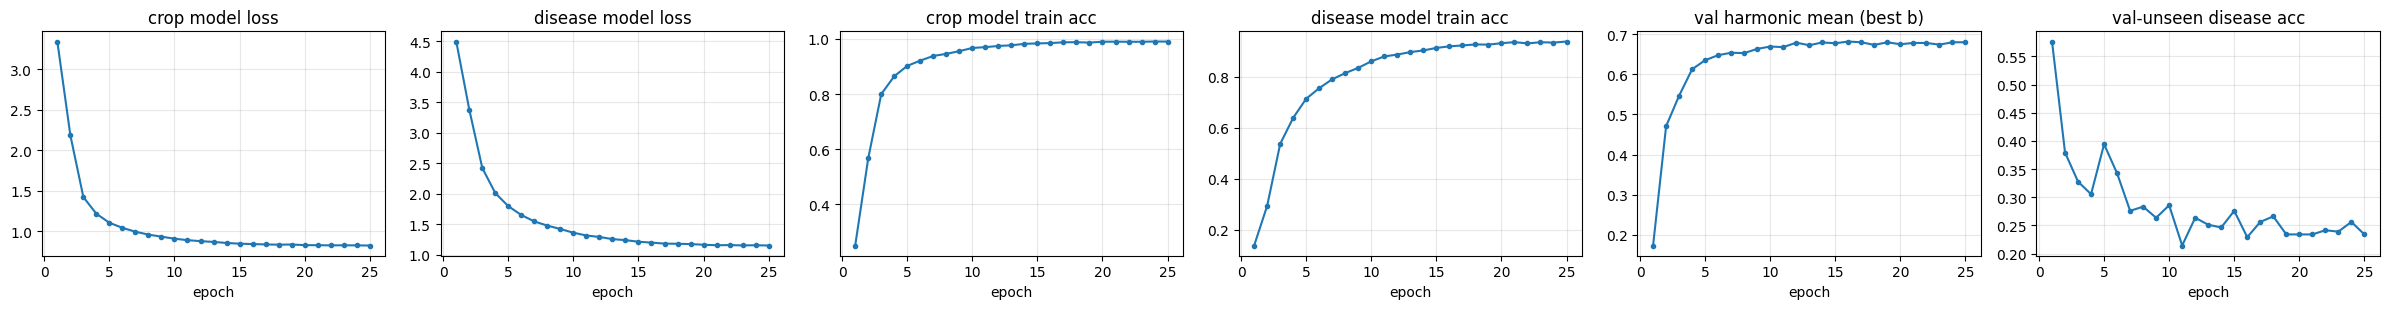

In [41]:
hist = pd.DataFrame(history)
panels = [('train_crop_loss', 'crop model loss'), ('train_disease_loss', 'disease model loss'),
          ('train_crop_acc', 'crop model train acc'), ('train_disease_acc', 'disease model train acc')]
if CFG['run_mode'] == 'dev':
    panels += [('val_best_hm', 'val harmonic mean (best b)'), ('val_unseen_disease_acc', 'val-unseen disease acc')]
fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 3.2))
for ax, (col, title) in zip(np.atleast_1d(axes), panels):
    ax.plot(hist['epoch'], hist[col], marker='o', ms=3)
    ax.set_title(title); ax.set_xlabel('epoch'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'training_curves.png'), dpi=150); plt.show()

## 12. Dev summary (dev mode only)
This saves the best epoch and bias. The final run reads them from `outputs/baseline1_independent_resnet50/dev/summary.json`.

{
  "best_epoch": 16,
  "best_bias": 4.287209510803223,
  "val_best_hm": 0.6813786434717423,
  "val_seen_at_best": 0.7664576768875122,
  "val_unseen_at_best": 0.6133005023002625,
  "val_auc": 0.5646146428209768,
  "holdout_pairs": [
    "apple_healthy",
    "blackgram_powdery_mildew",
    "broccoli_alternaria_leaf_spot",
    "broccoli_ring_spot",
    "cauliflower_bacterial_spot",
    "cauliflower_black_rot",
    "cherry_spot",
    "citrus_black_spot",
    "cucumber_angular_leaf_spot",
    "paddy_bacterial_blight",
    "papaya_curl",
    "plum_aphis_spp",
    "sugarcane_smut",
    "tea_healthy",
    "tomato_mosaic_virus"
  ]
}


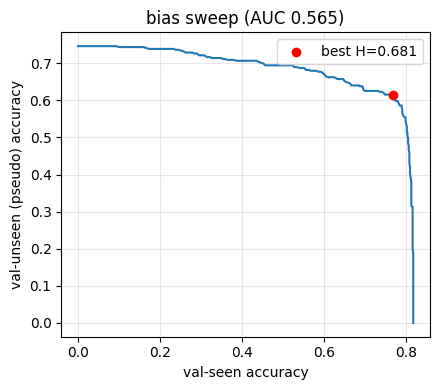

In [42]:
if CFG['run_mode'] == 'dev':
    best = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
    models.load_state_dict(best['models'])
    vs, vu = run_inference(models, val_seen_loader), run_inference(models, val_unseen_loader)
    sweep = bias_sweep(comp_scores(vs), vs['comp'], comp_scores(vu), vu['comp'])
    summary = dict(best_epoch=best['epoch'], best_bias=sweep['best_bias'], val_best_hm=sweep['best_hm'],
                   val_seen_at_best=sweep['best_seen'], val_unseen_at_best=sweep['best_novel'],
                   val_auc=sweep['auc'], holdout_pairs=[COMP_NAMES[c] for c in HOLDOUT], cfg=CFG)
    json.dump(summary, open(DEV_SUMMARY, 'w'), indent=2)
    print(json.dumps({k: v for k, v in summary.items() if k != 'cfg'}, indent=2))

    plt.figure(figsize=(4.5, 4))
    plt.plot(sweep['seen'], sweep['novel'], '-')
    plt.scatter([sweep['best_seen']], [sweep['best_novel']], c='r', zorder=3, label=f"best H={sweep['best_hm']:.3f}")
    plt.xlabel('val-seen accuracy'); plt.ylabel('val-unseen (pseudo) accuracy'); plt.legend()
    plt.title(f"bias sweep (AUC {sweep['auc']:.3f})"); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, 'val_bias_curve.png'), dpi=150); plt.show()

In [43]:
if CFG['run_mode'] != 'final':
    raise SystemExit('Dev run finished. Set run_mode="final" in the config cell and Run all again.')

SystemExit: Dev run finished. Set run_mode="final" in the config cell and Run all again.

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## 13. Final test evaluation
The headline numbers use the bias $b$ picked on the dev validation set. The "oracle" row uses the best $b$ *on the test set itself*. It's only an upper bound for the discussion and is never the reported result.

In [ ]:
models.load_state_dict(torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)['models'])
ts = run_inference(models, make_loader(test_seen_df, train=False))
tu = run_inference(models, make_loader(test_unseen_df, train=False))
S_test, U_test = comp_scores(ts), comp_scores(tu)
DEV_BIAS = json.load(open(DEV_SUMMARY))['best_bias'] if os.path.exists(DEV_SUMMARY) else 0.0
test_sweep = bias_sweep(S_test, ts['comp'], U_test, tu['comp'])

def report(bias):
    s1, u1 = topk_acc(S_test, ts['comp'], 1, bias), topk_acc(U_test, tu['comp'], 1, bias)
    return {'bias': round(bias, 3), 'seen top-1': s1, 'seen top-5': topk_acc(S_test, ts['comp'], 5, bias),
            'unseen top-1': u1, 'unseen top-5': topk_acc(U_test, tu['comp'], 5, bias),
            'harmonic mean': harmonic_mean(s1, u1)}

results = pd.DataFrame({
    'b = 0 (no calibration)': report(0.0),
    'b from dev validation (REPORTED)': report(DEV_BIAS),
    'oracle b on test (upper bound)': report(test_sweep['best_bias']),
}).T
display(results.style.format({c: '{:.2%}' for c in results.columns if c != 'bias'}))
print(f"seen/unseen AUC: {test_sweep['auc']:.4f}")

plt.figure(figsize=(4.5, 4))
plt.plot(test_sweep['seen'], test_sweep['novel'], '-')
r = report(DEV_BIAS)
plt.scatter([r['seen top-1']], [r['unseen top-1']], c='r', zorder=3, label=f"dev b, H={r['harmonic mean']:.3f}")
plt.xlabel('test-seen top-1'); plt.ylabel('test-unseen top-1'); plt.legend(); plt.grid(alpha=.3)
plt.title(f"Baseline 1 bias sweep (AUC {test_sweep['auc']:.3f})"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'test_bias_curve.png'), dpi=150); plt.show()

## 14. DPD paper protocol, and where the model fails
The DPD paper (Chai et al., ACM MM 2025) evaluates crop accuracy, disease accuracy and joint crop+disease accuracy, where each model predicts on its own (plain argmax, no pair list, no bias). A pair counts as correct only if both are right. We report this too, so our numbers can be compared with the paper's Table 4. That table uses the full DPD dataset, not DPD-Small, so it's a reference point rather than a like-for-like comparison.

If crop accuracy stays high on unseen images while disease accuracy drops, the disease model is the weak link. The **shortcut rate** is the share of wrong disease predictions on unseen images that name a disease the *true crop* had in training. A high rate means the disease model guesses the disease from the crop's appearance instead of from the symptoms. Comparing it with Baseline 2 shows whether separating the networks reduces this shortcut.

In [ ]:
def paper_protocol(out):
    pc, pdis = out['crop_lp'].argmax(1), out['dis_lp'].argmax(1)
    return {'crop acc': (pc == out['crop']).float().mean().item(),
            'disease acc': (pdis == out['disease']).float().mean().item(),
            'crop+disease acc': ((pc == out['crop']) & (pdis == out['disease'])).float().mean().item()}

head_table = pd.DataFrame({'test-seen': paper_protocol(ts), 'test-unseen': paper_protocol(tu)}).T
display(head_table.style.format('{:.2%}'))
PAPER_HM = harmonic_mean(head_table.at['test-seen', 'crop+disease acc'], head_table.at['test-unseen', 'crop+disease acc'])
print(f'paper-protocol harmonic mean: {PAPER_HM:.2%}  '
      '(paper Table 4, full DPD, ViT-B/16: seen 78.53%, unseen 2.69%, HM 5.20%)')

train_pairs = set(zip(fit_df['crop'], fit_df['disease']))
pred_dis = tu['dis_lp'].argmax(1)
wrong = pred_dis != tu['disease']
shortcut = [(int(c), int(d)) in train_pairs for c, d in zip(tu['crop'][wrong], pred_dis[wrong])]
SHORTCUT_RATE = float(np.mean(shortcut)) if shortcut else 0.0
print(f'unseen images with the wrong disease: {int(wrong.sum())}/{len(wrong)}')
print(f'shortcut rate (wrong disease is one the true crop had in training): {SHORTCUT_RATE:.2%}')

## 15. Confusion matrices (test-seen, with the dev bias)
The full 323-pair matrix is too dense to read pair by pair, so we also show the crop-level matrix and a table of the most-confused pairs. The full matrix is saved as CSV for the report.

In [ ]:
from sklearn.metrics import confusion_matrix
pred_seen = (S_test + DEV_BIAS * NOVEL_MASK.float()).argmax(1)
cm = confusion_matrix(ts['comp'].numpy(), pred_seen.numpy(), labels=list(range(NUM_COMPS)))
pd.DataFrame(cm, index=COMP_NAMES, columns=COMP_NAMES).to_csv(os.path.join(OUT_DIR, 'confusion_test_seen_pairs.csv'))

seen_ids = sorted(set(test_seen_df['comp']))
cm_seen = cm[np.ix_(seen_ids, seen_ids)].astype(float)
cm_norm = cm_seen / np.maximum(cm_seen.sum(1, keepdims=True), 1)
crop_cm = confusion_matrix(ts['crop'].numpy(), COMP_CROP[pred_seen].numpy(), labels=list(range(NUM_CROPS))).astype(float)
crop_norm = crop_cm / np.maximum(crop_cm.sum(1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
axes[0].imshow(cm_norm, cmap='viridis', vmin=0, vmax=1)
axes[0].set_title(f'test-seen confusion, {len(seen_ids)} seen pairs (row-normalised)')
axes[0].set_xlabel('predicted pair'); axes[0].set_ylabel('true pair')
im = axes[1].imshow(crop_norm, cmap='viridis', vmin=0, vmax=1)
axes[1].set_title('crop-level confusion (test-seen)')
axes[1].set_xticks(range(NUM_CROPS)); axes[1].set_xticklabels(CROP_NAMES, rotation=90, fontsize=5)
axes[1].set_yticks(range(NUM_CROPS)); axes[1].set_yticklabels(CROP_NAMES, fontsize=5)
fig.colorbar(im, ax=axes, shrink=.7)
plt.savefig(os.path.join(OUT_DIR, 'confusion_test_seen.png'), dpi=200, bbox_inches='tight'); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:15], off.shape))[0]
display(pd.DataFrame([dict(true=COMP_NAMES[i], predicted=COMP_NAMES[j], count=int(off[i, j]))
                      for i, j in top if off[i, j] > 0]))

## 16. What does each network's feature encode?
We take the test images whose disease appears in an unseen pair (diseases that occur on several crops). A **silhouette score** measures how cleanly features cluster by crop versus by disease. We check the crop model's feature, the disease model's feature, and both together.

The interesting one is the **disease model**: it was never given crop labels, so if its feature still clusters more by crop than by disease, it has learned crop appearance as a shortcut for disease on its own. Baseline 2 reports the same scores for its shared feature, so the two can be compared directly.

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

crop_lab = torch.cat([ts['crop'], tu['crop']]).numpy()
dis_lab = torch.cat([ts['disease'], tu['disease']]).numpy()
focus = np.isin(dis_lab, comps.loc[sorted(UNSEEN_COMPS), 'disease'].values)
c, d = crop_lab[focus], dis_lab[focus]

def safe_silhouette(x, y):
    return float(silhouette_score(x, y, metric='cosine')) if 1 < len(set(y)) < len(y) else float('nan')

feature_sets = {
    'crop model feature': F.normalize(torch.cat([ts['crop_feat'], tu['crop_feat']]), dim=1).numpy()[focus],
    'disease model feature': F.normalize(torch.cat([ts['dis_feat'], tu['dis_feat']]), dim=1).numpy()[focus],
    'both (UI feature)': torch.cat([ts['feat'], tu['feat']]).numpy()[focus],
}
SILHOUETTE = {name: {'by crop': safe_silhouette(f, c), 'by disease': safe_silhouette(f, d)}
              for name, f in feature_sets.items()}
print(f'{focus.sum()} images')
display(pd.DataFrame(SILHOUETTE).T.style.format('{:.3f}'))
SIL_CROP = SILHOUETTE['disease model feature']['by crop']
SIL_DIS = SILHOUETTE['disease model feature']['by disease']

if focus.sum() > 5:
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for row, name in enumerate(('crop model feature', 'disease model feature')):
        f = feature_sets[name]
        emb = TSNE(n_components=2, perplexity=min(30, len(f) - 1), init='pca', random_state=CFG['seed']).fit_transform(f)
        for col, (lab, lab_name) in enumerate(((c, 'crop'), (d, 'disease'))):
            ax = axes[row, col]
            ax.scatter(emb[:, 0], emb[:, 1], c=pd.factorize(lab)[0], cmap='tab20', s=6)
            ax.set_title(f'{name} coloured by {lab_name}'); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'tsne_crop_vs_disease.png'), dpi=150); plt.show()

## 17. Save metrics and the feature bank for the UI
`feature_bank.npz` holds the combined L2-normalised feature (crop model + disease model) for every training image. The UI uses it to show the training images that best match a query.

In [ ]:
bank = run_inference(models, make_loader(fit_df, train=False))
BANK_FEATS = F.normalize(bank['feat'], dim=1)
np.savez_compressed(os.path.join(OUT_DIR, 'feature_bank.npz'), feats=BANK_FEATS.numpy().astype(np.float16),
                    files=fit_df['file'].values, comp=bank['comp'].numpy(),
                    crop=bank['crop'].numpy(), disease=bank['disease'].numpy())

metrics = dict(model='Baseline 1: independent ResNet-50 (crop model + disease model)', epochs=EPOCHS, dev_bias=DEV_BIAS,
               results={k: v for k, v in results.to_dict(orient='index').items()},
               auc=test_sweep['auc'], heads=head_table.to_dict(orient='index'),
               paper_protocol_hm=PAPER_HM, shortcut_rate=SHORTCUT_RATE,
               silhouette_crop=SIL_CROP, silhouette_disease=SIL_DIS, silhouette_all=SILHOUETTE, cfg=CFG)
json.dump(metrics, open(os.path.join(OUT_DIR, 'metrics.json'), 'w'), indent=2)
print('saved to', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

## 18. Baseline 1 vs Baseline 2
If the Baseline 2 final run has been saved to the same Drive folder, this puts the two baselines side by side. Both use the same data, splits, hyperparameters and evaluation, so the only difference is **separate networks vs one shared backbone**. The silhouette rows compare Baseline 1's *disease model* feature with Baseline 2's *shared* feature.

In [ ]:
def summary_row(m):
    rep = m['results']['b from dev validation (REPORTED)']
    return {'seen top-1': rep['seen top-1'], 'seen top-5': rep['seen top-5'],
            'unseen top-1': rep['unseen top-1'], 'unseen top-5': rep['unseen top-5'],
            'harmonic mean': rep['harmonic mean'], 'seen/unseen AUC': m['auc'],
            'unseen crop acc (paper)': m['heads']['test-unseen']['crop acc'],
            'unseen disease acc (paper)': m['heads']['test-unseen']['disease acc'],
            'paper-protocol HM': m['paper_protocol_hm'], 'shortcut rate': m['shortcut_rate'],
            'silhouette by crop': m['silhouette_crop'], 'silhouette by disease': m['silhouette_disease']}

rows = {'Baseline 1: independent ResNet-50': summary_row(metrics)}
if os.path.exists(BASELINE2_METRICS):
    rows['Baseline 2: multi-task ResNet-50'] = summary_row(json.load(open(BASELINE2_METRICS)))
else:
    print('Baseline 2 metrics not found at', BASELINE2_METRICS, '(run its final pass to compare)')
comparison = pd.DataFrame(rows).T
pct = [col for col in comparison.columns if not col.startswith(('silhouette', 'seen/unseen'))]
display(comparison.style.format({**{col: '{:.2%}' for col in pct},
                                 **{col: '{:.3f}' for col in comparison.columns if col not in pct}}))
comparison.to_csv(os.path.join(OUT_DIR, 'baseline1_vs_baseline2.csv'))

## 19. Demo — identify one image
The UI flow: image in, top-5 crop + disease pairs out, plus the most similar training images.

In [ ]:
@torch.no_grad()
def identify(path, k=5, n_neighbours=5, bias=DEV_BIAS):
    models.eval()
    img = load_upright(path)
    x = eval_tf(img)[None].to(DEVICE)
    lc, fc = models['crop'](x)
    ld, fd = models['disease'](x)
    s = F.log_softmax(lc.float(), 1).cpu()[0][COMP_CROP] + F.log_softmax(ld.float(), 1).cpu()[0][COMP_DIS]
    s = s + bias * NOVEL_MASK.float()
    probs = s.softmax(0)
    top = probs.topk(k)
    preds = [(COMP_NAMES[i], float(p)) for p, i in zip(top.values, top.indices)]
    q = F.normalize(torch.cat([F.normalize(fc.float(), dim=1), F.normalize(fd.float(), dim=1)], dim=1), dim=1)
    sims = BANK_FEATS @ q.cpu()[0]
    nn_idx = sims.topk(n_neighbours).indices.tolist()

    fig, axes = plt.subplots(1, n_neighbours + 1, figsize=(3 * (n_neighbours + 1), 3.4))
    axes[0].imshow(img); axes[0].set_title('query\n' + '\n'.join(f'{n} {p:.0%}' for n, p in preds[:3]), fontsize=7)
    for ax, i in zip(axes[1:], nn_idx):
        ax.imshow(Image.open(os.path.join(IMAGE_DIR, fit_df['file'].iloc[i])).convert('RGB'))
        ax.set_title(f"{COMP_NAMES[int(fit_df['comp'].iloc[i])]}\nsim {sims[i]:.2f}", fontsize=7)
    for ax in axes:
        ax.axis('off')
    plt.tight_layout(); plt.show()
    return preds

sample = test_unseen_df.iloc[0]
print('true pair:', sample['comp_name'])
identify(os.path.join(IMAGE_DIR, sample['file']))